Queremos encontrar $\pi \in \text{Adm}(Q,q):=\bigl\{ \pi \in \mathbb{H}_{\ge}(\mathcal{H}) \ : \ \operatorname{Tr}[Q_i \pi] = q_i, \ 0 \le i \le M \bigr\}$ que minimiza a seguinte expressão:

$$ \mathcal{F}_\epsilon(\pi) = Tr[H\pi]+ \epsilon Tr[\pi(log \pi -1)]$$

Podemos encontrar a forma de $\pi$ como solução para  $\mathcal{F}_\epsilon$:

$$\pi^* = \text{exp}(\frac{1}{\epsilon}(\sum_{i=0}^M u_iQ_i - H))$$

Dessa forma, o "dual" do nosso problema regularizado assume a seguinte forma:

$$
\min_{u \in \mathbb{R}^{M+1}} \left\{ \epsilon \operatorname{Tr}\left[ \exp\left( \frac{\sum_{i=0}^M u_i Q_i - H}{\epsilon} \right) \right] - \sum_{i=0}^M u_i q_i \right\}
$$

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import least_squares


# Importa a biblioteca desenvolvida para o projeto
import quantum_tomography as qt

In [2]:

""" Tentando fazer um solver usando Gradient Descent """


def dual_cost(u, H, Q_list, q, epsilon):

    operator_sum = sum(u_i * Q_i for u_i, Q_i in zip(u, Q_list)) - H
    
    arg = operator_sum / epsilon

    exp_matrix = expm(arg)
    trace_val = np.real(np.trace(exp_matrix))

    cost = epsilon * trace_val - np.dot(u, q)
    return cost

def dual_gradient(u, H, Q_list, q, epsilon):
    
    operator_sum = sum(u_i * Q_i for u_i, Q_i in zip(u, Q_list)) - H
    arg = operator_sum / epsilon
    
    pi_u = expm(arg)
    
    grad = np.zeros_like(u, dtype=float)
    for i, Q_i in enumerate(Q_list):
        grad[i] = np.real(np.trace(Q_i @ pi_u)) - q[i]
        
    return grad

def gradient_descent(H, Q_list, q, epsilon, max_iters, lr, tol):

    u = np.zeros(len(q), dtype=float)  # Inicialização
    it = 0
    
    for k in range(max_iters):
        grad = dual_gradient(u, H, Q_list, q, epsilon)
        
        # Passo do Gradient Descent: u_{k+1} = u_k - lr * grad
        u_new = u - lr * grad
        
        if np.linalg.norm(grad) < tol:
            it = k
            break
            
        u = u_new
    return [u, it]

def reconstruct_pi(H, Q_list, q, epsilon, max_iters, lr=0.01, tol=1e-6):
    u_opt = gradient_descent(H, Q_list, q, epsilon, max_iters, lr, tol)
    operator_sum = sum(u_i * Q_i for u_i, Q_i in zip(u_opt[0], Q_list)) - H
    return [expm(operator_sum / epsilon), u_opt[0], u_opt[1]]
    

In [3]:
# Teste básico
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

pistar = reconstruct_pi(H, Q, q, epsilon, lr=0.01, max_iters=5000, tol=1e-6)[0]
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Matriz reconstruída pi*:")
print(pistar)

(1.0000053605606762+2.255192533269142e-17j) (0.6999953457299546+5.551115123125783e-17j) (0.3999973404171167-5.551115123125783e-17j)
Matriz reconstruída pi*:
[[0.50000268-3.01695856e-17j 0.34999767-1.99998670e-01j]
 [0.34999767+1.99998670e-01j 0.50000268+5.27215109e-17j]]


In [4]:
# Teste variando epsilon e learning rate
epsilon_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

pieps = []
piepsit = []
pilr = []
pilrit = []

for epsilon in epsilon_values:
    result = reconstruct_pi(H, Q, q, epsilon, lr=0.01, max_iters=100000, tol=1e-6)
    pieps.append(result[0])
    piepsit.append(result[2])

for lr in lr_values:
    result = reconstruct_pi(H, Q, q, epsilon=1.0, lr=lr, max_iters=100000, tol=1e-6)
    pilr.append(result[0])
    pilrit.append(result[2])

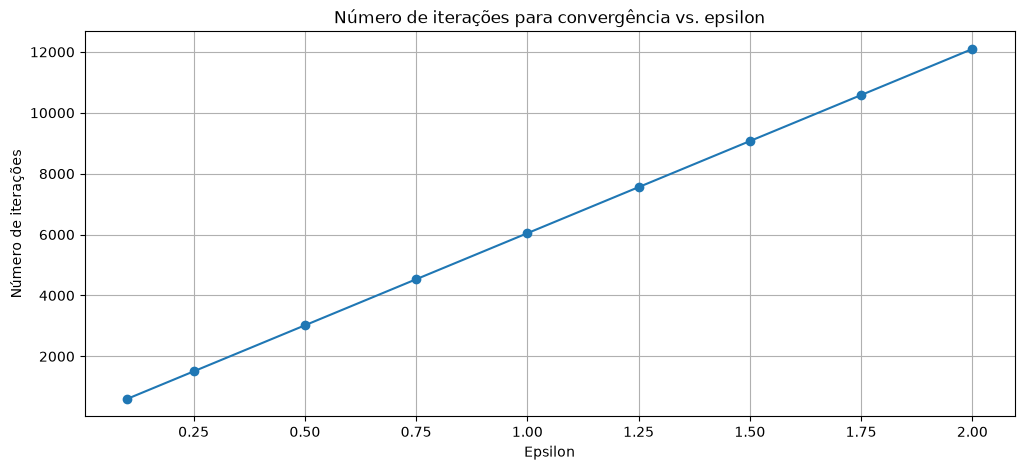

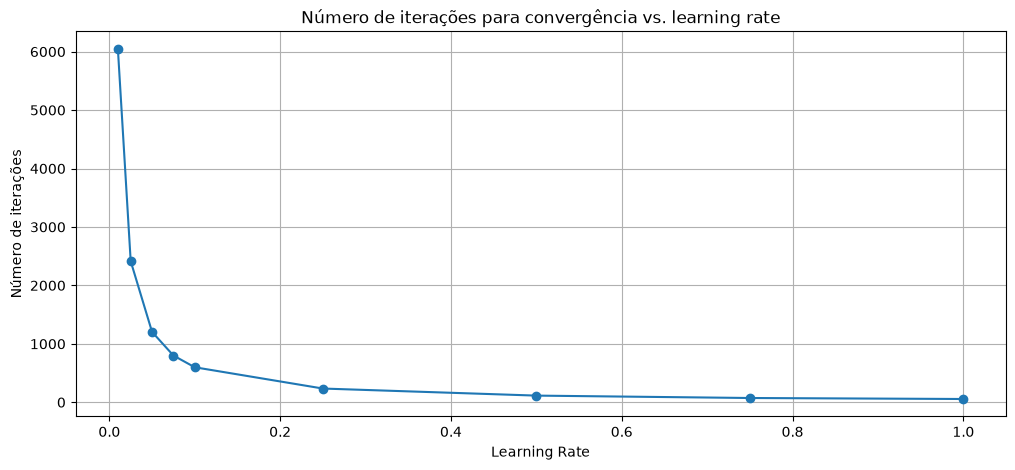

In [5]:
plt.figure(figsize=(12, 5))
plt.plot(epsilon_values, piepsit, marker='o')
plt.title("Número de iterações para convergência vs. epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Número de iterações")
plt.grid()

plt.figure(figsize=(12, 5))
plt.plot(lr_values, pilrit, marker='o')
plt.title("Número de iterações para convergência vs. learning rate")
plt.xlabel("Learning Rate")
plt.ylabel("Número de iterações")
plt.grid()

In [ ]:
# Tentando fazer o Stochastic Method

def stochastic_gradient(u, H, Q_list, q, epsilon, rng=None, k=None):

    rng = np.random.default_rng() if rng is None else rng
    m = len(u)
    k = m if k is None else min(k, m)

    operator_sum = sum(u_i * Q_i for u_i, Q_i in zip(u, Q_list)) - H
    pi_u = expm(operator_sum / epsilon)

    idx = rng.choice(m, size=k, replace=False)   # direções sorteadas

    grad = np.zeros(m, dtype=float)
    for i in idx:
        grad[i] = np.real(np.sum(Q_list[i] * pi_u.T)) - q[i]
        
    return grad, idx


def sgd(H, Q_list, q, epsilon, k, lr=0.1, n_iter=10000, seed=0, u0=np.zeros(len(q), dtype=float) ):

    rng = np.random.default_rng(seed)
    u = u0.copy()
    for t in range(n_iter):
        grad, idx = stochastic_gradient(u, H, Q_list, q, epsilon, k=k, rng=rng)
        u -= lr * grad         
        
    return u

def reconstruct_spi(H, Q_list, q, epsilon, max_iters, lr=0.01, tol=1e-6):
    u_opt = sgd(H, Q_list, q, epsilon, max_iters, lr, tol)
    operator_sum = sum(u_i * Q_i for u_i, Q_i in zip(u_opt[0], Q_list)) - H
    return [expm(operator_sum / epsilon), u_opt[0], u_opt[1]]

In [ ]:
# Teste básico
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

pistar = reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=0.01, tol=1e-6)[0]
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Matriz reconstruída pi*:")
print(pistar)

TypeError: 'float' object cannot be interpreted as an integer

In [ ]:
# Teste variando epsilon e learning rate
epsilon_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

pieps = []
piepsit = []
pilr = []
pilrit = []

for epsilon in epsilon_values:
    result = reconstruct_spi(H, Q, q, epsilon, lr=0.01, max_iters=100000, tol=1e-6)
    pieps.append(result[0])
    piepsit.append(result[2])

for lr in lr_values:
    result = reconstruct_spi(H, Q, q, epsilon=1.0, lr=lr, max_iters=100000, tol=1e-6)
    pilr.append(result[0])
    pilrit.append(result[2])

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(epsilon_values, piepsit, marker='o')
plt.title("Número de iterações para convergência vs. epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Número de iterações")
plt.grid()

plt.figure(figsize=(12, 5))
plt.plot(lr_values, pilrit, marker='o')
plt.title("Número de iterações para convergência vs. learning rate")
plt.xlabel("Learning Rate")
plt.ylabel("Número de iterações")
plt.grid()